# Neglecting Uncertainties Can Understate Risk

Code adapted from the [Risk Interactions Flood GitHub Repository](https://github.com/imshakib/Risk_Interactions_Flood) by Iman Hosseini-Shakib and Klaus Keller

First, install and load relevant packages.

In [37]:
if (!require('VGAM')) {install.packages('VGAM')}
if (!require('ggplot2')) {install.packages('ggplot2')}
if (!require('ggpubr')) {install.packages('ggpubr')}
if (!require('ggExtra')) {install.packages('ggExtra')}
library(VGAM)
library(ggplot2)
library(ggpubr)
library(ggExtra)
library(dplyr)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




Define parameters and depth damage functions.

In [9]:
nsamp <- 1e5 # how many samples per distribution?

# A logistic function to mimic the S-shaped depth-damage curve with water levels (WL) and coefficients a and k
logistic <- function(WL,k,a){
  (1/(1+exp(-k*WL)))^a
} 

# Water level distribution characteristics
WL=1:1000   #hypothetical water levels
meanWL=525 #hypothetical mean water level for the stationary pdf
sdWL=65 #hypothetical standard deviation of the stationary pdf
meanWL_nonS=550 #hypothetical mean water level for the non-stationary pdf
sdWL_nonS=150 #hypothetical standard deviation of the non-stationary pdf
shapeWL_nonS=5 #hypothetical shape factor of the non-stationary pdf

# Hazard
WLbest=WL[meanWL] #hypothetical best guess stationary water level
# obtain samples from distributions
wl_stat_samp <- rnorm(nsamp,meanWL,sdWL) #hypothetical distribution of water levels - stationary with uncertainty
wl_nonstat_samp <- rskewnorm(nsamp,location=meanWL_nonS,scale=sdWL_nonS,shape=shapeWL_nonS) #hypothetical distribution of water levels - non-stationary with uncertainty

# Vulnerability
dmg_nolevee <- logistic((0.015*WL)-11,0.8,0.6) #hypothetical damages - without levee effect
LEV=1.3 #hypothetical levee effect coefficient
dmg_levee <- dmg_nolevee * LEV #hypothetical damages - with levee effect 

# Risk
rsk_nounc_nolevee <- dmg_nolevee[WLbest] # hypothetical risk with stationary best guess hazard and depth-damage function without levee effect 
rsk_stat_nolevee <- logistic((0.015*wl_stat_samp)-11, 0.8, 0.6) # hypothetical risk pdf with stationary with uncertainty pdf and depth-damage function without levee effect
rsk_nonstat_nolevee <- logistic((0.015*wl_nonstat_samp)-11, 0.8, 0.6) # hypothetical risk pdf with non-stationary with uncertainty pdf and depth-damage function without levee effect
rsk_nonstat_levee <- logistic((0.015*wl_nonstat_samp)-11, 0.8, 0.6) * LEV# hypothetical risk pdf with non-stationary with uncertainty pdf and levee effect

dat_stat_nolevee <- data.frame(wl=wl_stat_samp, dmg=rsk_stat_nolevee, group='stat_nolevee')
dat_nonstat_nolevee <- data.frame(wl=wl_nonstat_samp, dmg=rsk_nonstat_nolevee, group='nonstat_nolevee')
dat_nonstat_levee <- data.frame(wl=wl_nonstat_samp, dmg=rsk_nonstat_levee, group='nonstat_levee')
dat_all <- rbind(dat_stat_nolevee, dat_nonstat_nolevee, dat_nonstat_levee)

dat_dmg_nolevee <- data.frame(wl=WL, dmg=dmg_nolevee, group="nolevee")
dat_dmg_levee <- data.frame(wl=WL, dmg=dmg_levee, group="levee")
dat_dmg_all <- rbind(dat_dmg_nolevee, dat_dmg_levee)
  

## Plot a

In [63]:
dens_wl <- density(wl_stat_samp)
a<-ggplot(dat_all[dat_all$group %in% c('nonstat_nolevee'),], aes(x=wl,group=group)) +
  geom_density(aes(color=group),size=1.5)+
  scale_colour_manual(name = '', 
                      values =c(nonstat_nolevee='darkblue'))+
  scale_x_continuous("Water Levels", expand = c(0, 0), limits=c(0, 1100)) + 
  scale_y_continuous("Probability Density", expand = c(0, 0)) +
  annotate("segment", x = WLbest, xend = WLbest, y = 0, yend = max(dens_wl$y),
         linewidth = 1, color = "black") +
  annotate(x=580,y=0.006, geom="text",
            label="Neglecting uncertainty",
            color="black",size=6,lineheight = .75,hjust="left")+
  annotate(x=725,y=0.004,geom="text",
            label="Considering \nuncertainty",
            color="darkblue",size=6,lineheight = .75,hjust="left")+
  theme_classic()+
  theme(axis.text = element_blank(),
        axis.ticks = element_blank(),
        axis.title.x = element_text(size=18, face="bold"),
        axis.title.y = element_text(size=18, face="bold"),
        legend.text=element_text(size=18),
        legend.position = "none",panel.grid.major = element_blank(), panel.grid.minor = element_blank(),
        axis.line = element_line(arrow = arrow(angle = 15, length = unit(0.2, "inches"),type = "closed"))) +
  coord_cartesian(ylim=c(0, 0.007))

Warning message:
“Removed 31 rows containing non-finite outside the scale range
(`stat_density()`).”


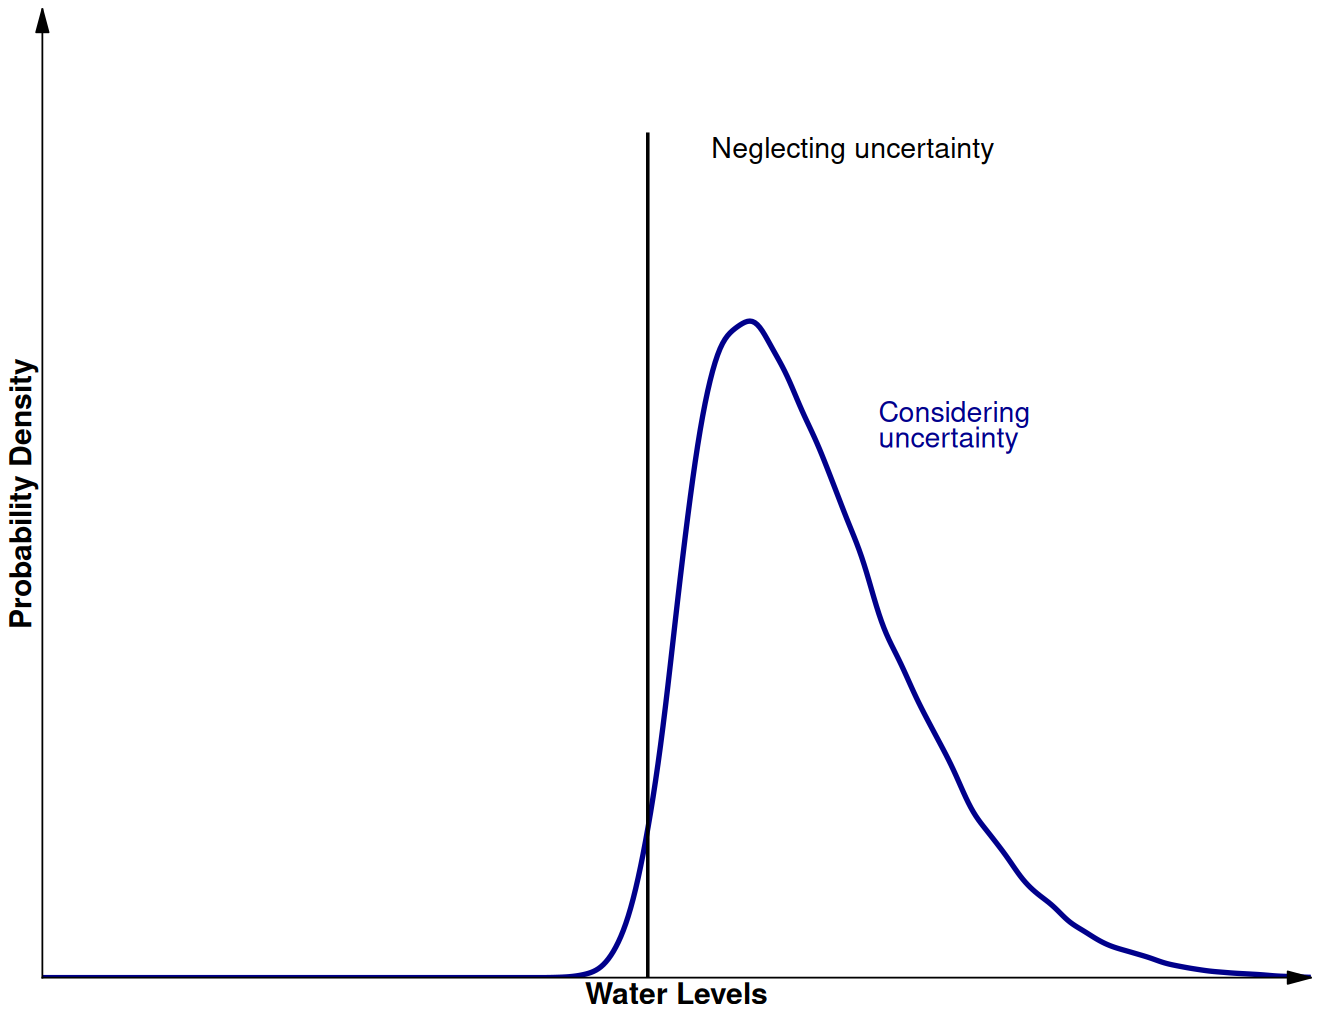

In [64]:
a

## Plot b

In [52]:
# Plot b - Vulnerability
b<-ggplot(dat_dmg_all,aes(x=wl, y=dmg, group=group))+
  geom_line(aes(color=group),size=1.5)+
  scale_colour_manual(name = '', 
                      values =c(nolevee='darkkhaki',levee='darkgreen'))+
  scale_x_continuous("Water Levels", expand = c(0, 0), limits = c(0, 1100)) + 
  scale_y_continuous("Damages", expand = c(0, 0), limits = c(0, 1.1*max(dat_dmg_levee$dmg))) + 
  annotate(x=525,y=0.6*max(dat_dmg_levee$dmg), geom="text",
            label="Considering\nlevee effect", color="darkgreen",
            size=6,lineheight = .75)+
  annotate(x=775,y=0.25*max(dat_dmg_levee$dmg), geom="text",
            label="Neglecting\nlevee effect", color="darkkhaki",
            size=6,lineheight = .75)+
  theme_classic()+
  theme(axis.text = element_blank(),
        axis.ticks = element_blank(),
        axis.title.x = element_text(size=18, face="bold"),
        axis.title.y = element_text(size=18, face="bold"),
        legend.text=element_text(size=18),
        legend.position =  "none",panel.grid.major = element_blank(), panel.grid.minor = element_blank(),
        axis.line = element_line(arrow = arrow(angle = 15, length = unit(0.2, "inches"),type = "closed")))

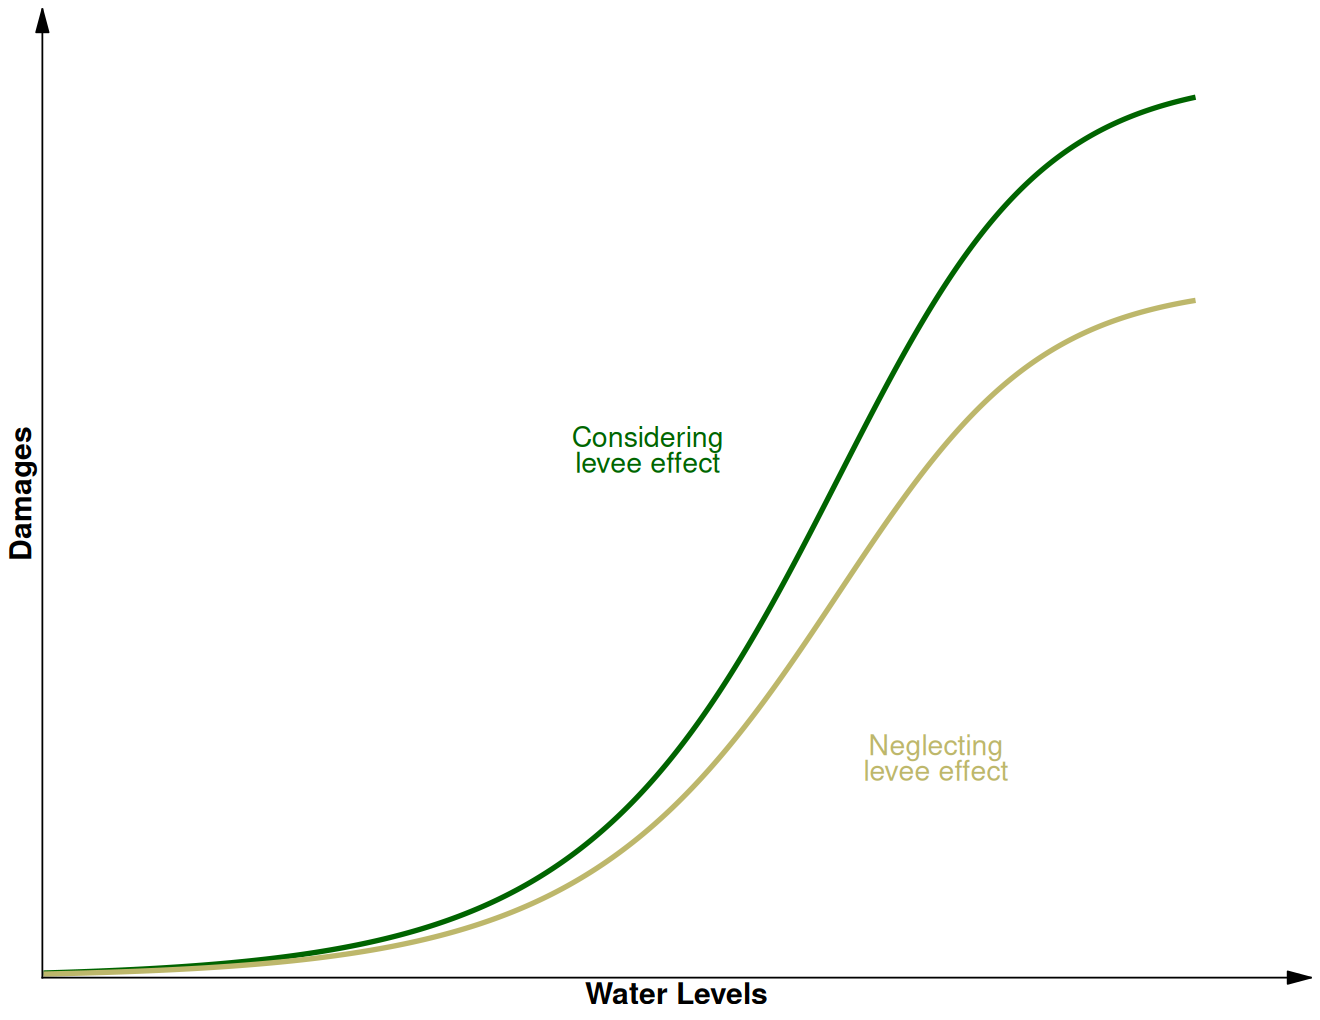

In [53]:
b

## Plot c

In [59]:
# Plot c - Risk
dat_all <- dat_all %>% filter(group != 'stat_nolevee')
c<-ggplot(dat_all,aes(x=dmg, group=group))+
  geom_density(aes(color=group),size=1.5)+
  annotate("segment", x = rsk_nounc_nolevee, xend = rsk_nounc_nolevee, y = 0, yend = 9,
         linewidth = 1, colour = "black") +
  annotate(x=mean(rsk_nonstat_levee),y=9, geom="point",size=4,color="darkred")+
  annotate(x=mean(rsk_nonstat_nolevee),y=9, geom="point",size=4,color="orangered1")+
  scale_colour_manual(name = '', 
                      values =c(nonstat_levee='darkred',nonstat_nolevee='orangered1')) +
  scale_x_continuous("Damages", expand = c(0, 0), limits = c(0, 1.4)) + 
  scale_y_continuous("Probability Density", expand = c(0, 0), limits = c(0, 9.5)) + 
  annotate("label", x = mean(c(mean(rsk_nonstat_nolevee), mean(rsk_nonstat_levee))), y = 7.7, label = "Expected\nvalues",
           size = 6, lineheight = .75, fill = "lightgray") +
  annotate(x=0.28,y=7.5, geom="text",
            label="Neglecting all",
            color="black",size=6,hjust="right",lineheight = .75)+
  annotate(x=1.2,y=0.9, geom="text",
            label="Considering all",
            hjust="left",color="darkred",size=6,lineheight = .75)+
  geom_segment(x=1.2,y=0.85,xend = 1.2,yend = 0.5,
               size=0.5,color="darkred",arrow = arrow(angle = 15, length = unit(0.1, "inches")))+
  annotate(x=0.95,y=1.5, geom="text",
            label="Neglecting levee effect", 
            hjust="left",color="orangered1",size=6,lineheight = .75)+
  geom_segment(x=0.95,y=1.45,xend = 0.95,yend = 0.48,
               size=0.5,color="orangered1",arrow = arrow(angle = 15, length = unit(0.1, "inches")))+
  theme_classic()+
  theme(axis.text = element_blank(),
        axis.ticks = element_blank(),
        axis.title.x = element_text(size=18, face="bold"),
        axis.title.y = element_text(size=18, face="bold"),
        legend.text=element_text(size=18),
        legend.position =  "none",panel.grid.major = element_blank(), panel.grid.minor = element_blank(),
        axis.line = element_line(arrow = arrow(angle = 15, length = unit(0.2, "inches"),
                                               type = "closed")))+
  coord_flip()

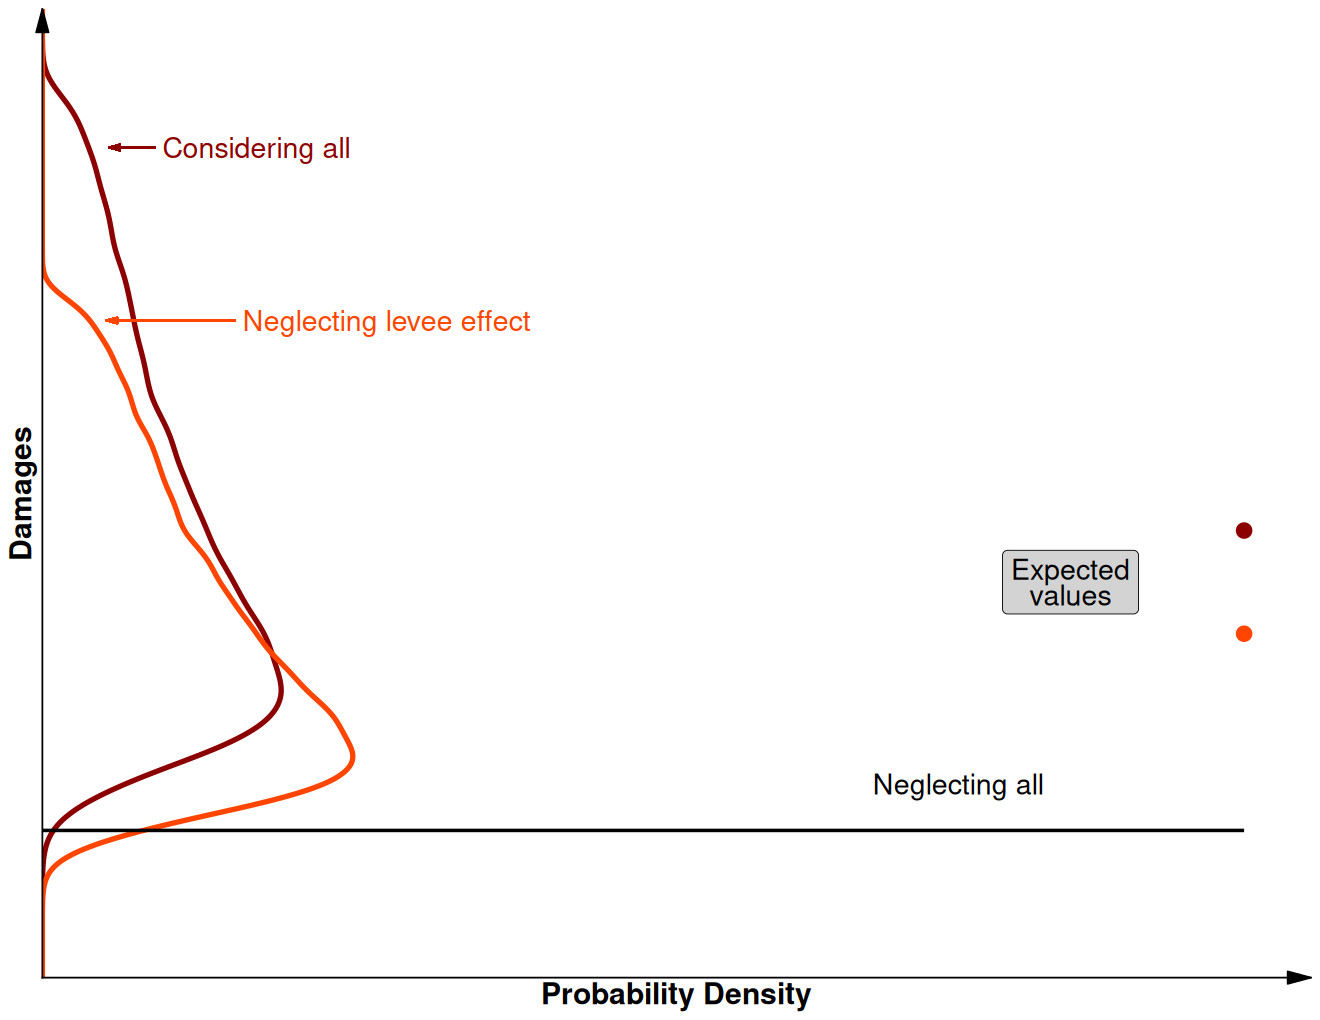

In [60]:
c

## Putting it all together

Warning message:
“Removed 31 rows containing non-finite outside the scale range
(`stat_density()`).”


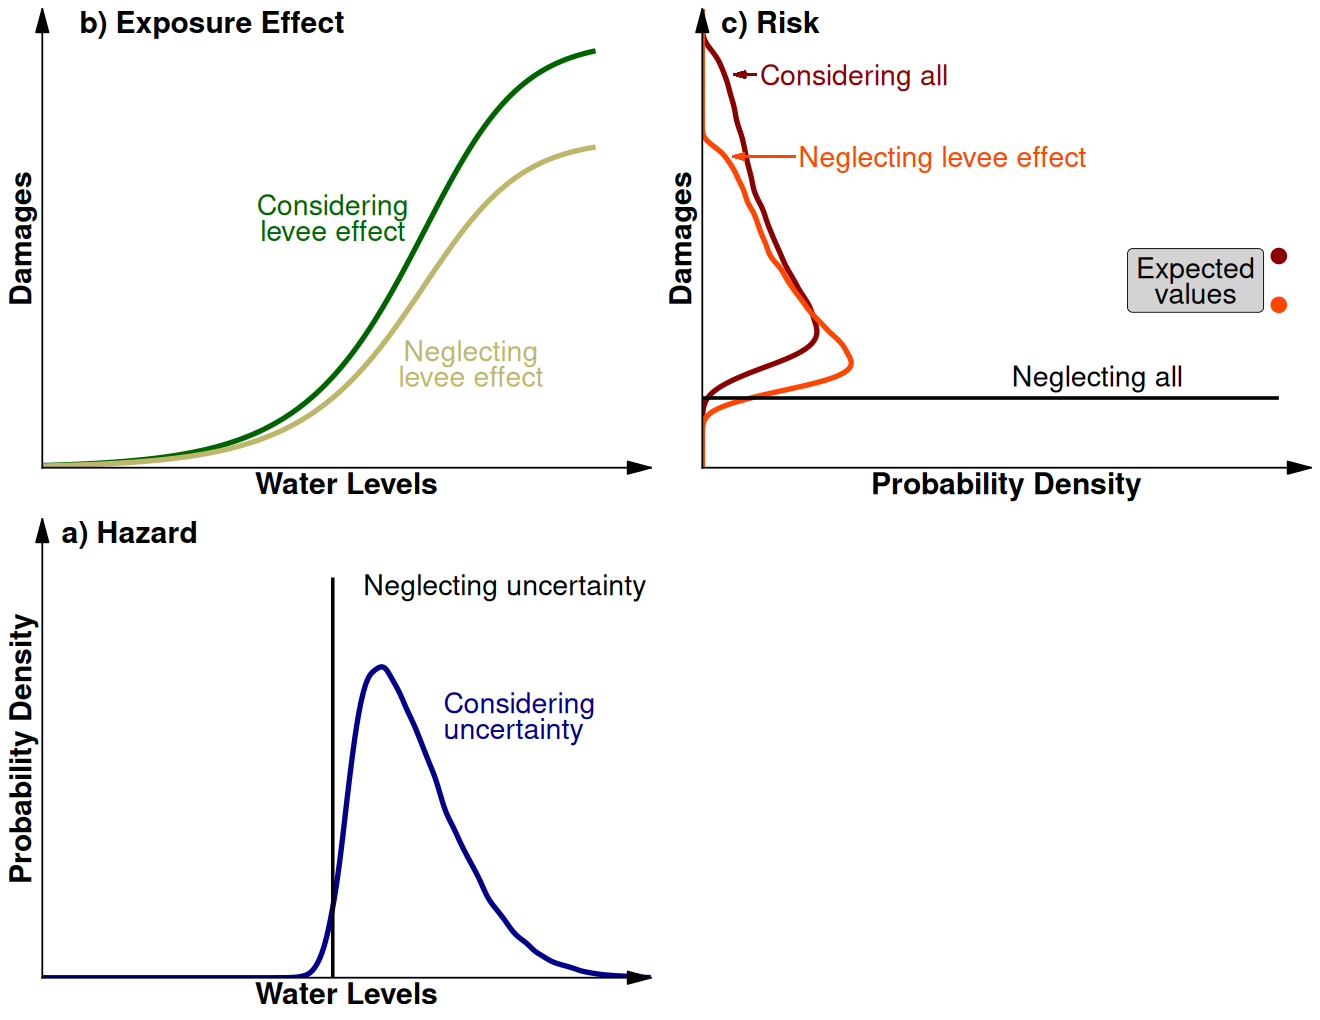

In [65]:
# Organizing plots
options(repr.plot.width = 11, repr.plot.height = 8.5)

figure1 <- ggarrange(b,c,a,
                     labels = c("b) Exposure Effect","   c) Risk","  a) Hazard"),
                     font.label = list(size = 18),
                     vjust =1.5, hjust =-.3,
                     ncol = 2, nrow = 2)

figure1

In [66]:
# Coordinates of the start and end points of the leader line
x1=0.254; y1=0.40
x2=0.53; y2=0.615
# Adding leader lines and arrowheads 
figure<-figure1+geom_segment(aes(x=x1,xend=x1,y=y1,yend=y2),size=1,linetype="dotted")+
  geom_segment(aes(x=x1,xend=x1,y=y2-0.01,yend=y2),arrow = arrow(angle = 15, length = unit(0.2, "inches"),type="closed"))+
  geom_segment(aes(x=x1,xend=x2,y=y2,yend=y2),size=1,linetype="dotted")+
  geom_segment(aes(x=x2-0.01,xend=x2,y=y2,yend=y2),arrow = arrow(angle = 15, length = unit(0.2, "inches"),type="closed"))

# Saving a JPG and PDF file of the plot
ggsave("Risk_Interactions.jpg",width = 11, height = 8.5, units = c("in"),dpi = 600)
ggsave("Risk_Interactions.pdf",width = 11, height = 8.5, units = c("in"),dpi = 600)